# 6장. 데이터를 보며 질문을 만드는 EDA

이 노트북은 `book/chapters/ch06_eda_questions.md` 강의안을 초보자가 그대로 따라 하며 이해할 수 있도록 구성한 실습 자료입니다.

이번 장의 핵심은 그래프나 표를 많이 만드는 것이 아니라, 데이터를 보며 **현재 데이터로 답할 수 있는 질문**을 만들고 그 질문을 지표와 코드로 연결하는 것입니다.


## 0. 이 노트북 사용 방법

아래 셀을 위에서부터 차례대로 실행하세요.

- 이 노트북은 5장에서 만든 `data/processed/*_clean.csv` 파일을 사용합니다.
- 전처리 파일이 없다면 먼저 `python scripts/preprocess_data.py`를 실행하세요.
- EDA 결과표는 `reports/` 폴더에 CSV와 Markdown 보고서로 저장합니다.
- EDA 결과는 최종 결론이 아니라, 다음 분석 질문을 만드는 중간 산출물입니다.


## 1. EDA는 결론보다 질문에 가깝다

EDA는 Exploratory Data Analysis, 즉 탐색적 데이터 분석입니다. 이름 그대로 데이터를 여러 방향에서 탐색하면서 분포, 패턴, 차이, 관계, 이상한 값을 발견하는 과정입니다.

EDA에서 자주 던지는 질문은 다음과 같습니다.

- 데이터는 어떤 변수들로 구성되어 있는가?
- 주요 숫자형 변수의 분포는 어떤가?
- 주요 범주형 변수의 빈도는 어떤가?
- 특정 그룹 간 차이가 있는가?
- 시간에 따른 변화가 있는가?
- 이상하게 큰 값이나 작은 값이 있는가?
- 다음 단계에서 더 깊이 볼 질문은 무엇인가?


## 2. 관찰, 가설, 결론 구분하기

EDA 결과를 해석할 때는 관찰, 가설, 결론을 구분해야 합니다.

| 구분 | 의미 | 예시 |
|---|---|---|
| 관찰 | 데이터에서 직접 확인한 사실 | 전자기기 카테고리의 매출 비중이 가장 높다 |
| 가설 | 관찰을 바탕으로 생각해 볼 가능성 | 전자기기는 단가가 높아 매출 비중이 클 수 있다 |
| 결론 | 추가 검증 후 말할 수 있는 판단 | 단가와 판매 수량을 함께 분석한 결과 매출 차이의 주요 요인은 단가였다 |

이번 장에서는 주로 관찰과 가설을 만들고, 다음 분석 질문으로 연결하는 연습을 합니다.


## 3. 좋은 분석 질문의 조건

좋은 분석 질문은 데이터로 답할 수 있어야 합니다.

| 조건 | 설명 | 예시 |
|---|---|---|
| 데이터 기반 | 현재 데이터로 답할 수 있어야 함 | 월별 매출은 어떻게 변하는가? |
| 구체적 | 분석 대상과 기준이 명확해야 함 | 카테고리별 매출 비중은 어떻게 다른가? |
| 측정 가능 | 지표로 계산할 수 있어야 함 | 주문 수, 총매출, 평균 구매 금액 |
| 해석 가능 | 결과가 다음 판단과 연결되어야 함 | 어떤 상품군을 더 자세히 봐야 하는가? |
| 검증 가능 | 코드로 확인할 수 있어야 함 | `groupby()`로 계산 가능 |


## 4. 패키지와 경로 설정

노트북이 `notebooks/` 폴더 안에서 실행되는 경우와 프로젝트 루트에서 실행되는 경우를 모두 고려해 경로를 설정합니다.


In [ ]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np


def find_chapter_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if candidate.name == "chapter06" and (candidate / "data" / "processed").exists():
            return candidate
        nested = candidate / "chapter06"
        if (nested / "data" / "processed").exists():
            return nested
    raise FileNotFoundError("chapter06/data/processed 폴더를 찾지 못했습니다.")


CHAPTER_ROOT = find_chapter_root(Path.cwd())
PROCESSED_DIR = CHAPTER_ROOT / "data" / "processed"
REPORT_DIR = CHAPTER_ROOT / "reports"
REPORT_DIR.mkdir(exist_ok=True)

if str(CHAPTER_ROOT) not in sys.path:
    sys.path.insert(0, str(CHAPTER_ROOT))

print("Chapter 06 폴더:", CHAPTER_ROOT)
print("전처리 데이터 폴더:", PROCESSED_DIR)


Chapter 06 폴더: C:\Users\신윤철\Documents\llm-data-analysis-study\chapter06
전처리 데이터 폴더: C:\Users\신윤철\Documents\llm-data-analysis-study\chapter06\data\processed


## 5. 전처리된 데이터 불러오기

6장은 5장에서 저장한 전처리 데이터를 사용합니다. 전처리 파일이 없다면 먼저 아래 명령을 터미널에서 실행하세요.

```bash
python scripts/preprocess_data.py
```


In [ ]:
required_files = [
    PROCESSED_DIR / 'customers_clean.csv',
    PROCESSED_DIR / 'products_clean.csv',
    PROCESSED_DIR / 'orders_clean.csv',
    PROCESSED_DIR / 'order_items_clean.csv',
]

missing_files = [path for path in required_files if not path.exists()]

if missing_files:
    for path in missing_files:
        print('누락 파일:', path)
    raise FileNotFoundError('전처리 파일이 없습니다. 먼저 python scripts/preprocess_data.py 를 실행하세요.')

customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
products = pd.read_csv(PROCESSED_DIR / 'products_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

print('전처리 데이터 불러오기 완료')


전처리 데이터 불러오기 완료


## 6. 데이터 크기와 컬럼 확인하기

EDA를 시작하기 전에 각 데이터의 행/열 수와 컬럼명을 다시 확인합니다. CSV로 저장했다가 다시 불러오면 날짜 컬럼이 문자열로 돌아올 수 있으므로 날짜형 변환도 다시 확인합니다.


In [ ]:
data = {
    'customers': customers,
    'products': products,
    'orders': orders,
    'order_items': order_items,
}

for name, df in data.items():
    print(f'[{name}]')
    print('shape:', df.shape)
    print('columns:', list(df.columns))
    print()


[customers]
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']

[products]
shape: (96, 4)
columns: ['product_id', 'product_name', 'category', 'price']

[orders]
shape: (300, 7)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status', 'order_month', 'order_dayofweek']

[order_items]
shape: (752, 6)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price', 'line_total']



In [ ]:
orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')

if 'signup_date' in customers.columns:
    customers['signup_date'] = pd.to_datetime(customers['signup_date'], errors='coerce')

if 'order_month' not in orders.columns:
    orders['order_month'] = orders['order_date'].dt.to_period('M').astype(str)

print('order_date 변환 실패:', orders['order_date'].isna().sum())
print('주문 시작일:', orders['order_date'].min())
print('주문 종료일:', orders['order_date'].max())


order_date 변환 실패: 3
주문 시작일: 2025-07-01 00:00:00
주문 종료일: 2028-12-31 00:00:00


## 7. 분석 질문을 먼저 표로 정리하기

EDA를 시작하기 전에 어떤 질문을 볼지 먼저 표로 정리하면 분석이 산만해지지 않습니다. 아래 표는 고객, 상품, 주문, 매출, 시간, 고객 가치 관점에서 만들 수 있는 기본 질문입니다.


In [ ]:
questions = pd.DataFrame({
    'analysis_area': ['고객', '상품', '주문', '매출', '시간', '고객 가치'],
    'question': [
        '고객은 어떤 지역과 연령대에 분포하는가?',
        '어떤 카테고리의 상품이 많은가?',
        '주문 상태와 결제수단 분포는 어떤가?',
        '카테고리별 매출은 어떻게 다른가?',
        '월별 매출과 주문 수는 어떻게 변하는가?',
        '구매 금액이 높은 고객은 누구인가?',
    ],
    'metric': [
        '고객 수, 평균 나이',
        '카테고리별 상품 수',
        '주문 수, 비율',
        '총매출, 매출 비중',
        '월별 매출, 월별 주문 수',
        '고객별 총매출, 주문 횟수',
    ],
    'required_data': [
        'customers',
        'products',
        'orders',
        'order_items, products',
        'orders, order_items',
        'customers, orders, order_items',
    ],
})

questions


,analysis_area,question,metric,required_data
0,고객,고객은 어떤 지역과 연령대에 분포하는가?,"고객 수, 평균 나이",customers
1,상품,어떤 카테고리의 상품이 많은가?,카테고리별 상품 수,products
2,주문,주문 상태와 결제수단 분포는 어떤가?,"주문 수, 비율",orders
3,매출,카테고리별 매출은 어떻게 다른가?,"총매출, 매출 비중","order_items, products"
4,시간,월별 매출과 주문 수는 어떻게 변하는가?,"월별 매출, 월별 주문 수","orders, order_items"
5,고객 가치,구매 금액이 높은 고객은 누구인가?,"고객별 총매출, 주문 횟수","customers, orders, order_items"


## 8. 고객 데이터 EDA

먼저 고객 데이터만 따로 살펴봅니다. 하나의 데이터셋 안에서 분포와 빈도를 확인하면 이후 병합 분석을 할 때 기준이 생깁니다.


In [ ]:
customers['age'].describe()


count    150.000000
mean      43.913333
std       17.802397
min       18.000000
25%       30.000000
50%       41.000000
75%       56.750000
max      150.000000
Name: age, dtype: float64

In [ ]:
customer_city = customers['city'].value_counts(dropna=False).reset_index()
customer_city.columns = ['city', 'customer_count']
customer_city['customer_ratio'] = (
    customer_city['customer_count'] / customer_city['customer_count'].sum() * 100
).round(2)

customer_city


,city,customer_count,customer_ratio
0,부산,23,15.33
1,대구,21,14.00
2,광주,21,14.00
3,서울,18,12.00
4,울산,17,11.33
5,인천,16,10.67
6,수원,10,6.67
7,성남,9,6.00
8,고양,8,5.33
9,대전,5,3.33


In [ ]:
customer_gender = customers['gender'].value_counts(dropna=False).reset_index()
customer_gender.columns = ['gender', 'customer_count']
customer_gender['customer_ratio'] = (
    customer_gender['customer_count'] / customer_gender['customer_count'].sum() * 100
).round(2)

customer_gender


,gender,customer_count,customer_ratio
0,M,80,53.33
1,F,70,46.67


고객 데이터에서 이어질 수 있는 질문은 다음과 같습니다.

- 고객은 어느 도시에 많이 분포하는가?
- 고객의 평균 나이는 어느 정도인가?
- 성별 고객 수는 어떻게 분포하는가?
- 도시별 구매 금액도 차이가 있는가?


## 9. 상품 데이터 EDA

상품 데이터에서는 카테고리와 가격을 먼저 봅니다. 상품 수가 많은 카테고리가 매출도 높은지는 아직 알 수 없습니다. 그것은 주문 상세와 연결한 뒤 확인해야 합니다.


In [ ]:
product_category = products['category'].value_counts(dropna=False).reset_index()
product_category.columns = ['category', 'product_count']
product_category['product_ratio'] = (
    product_category['product_count'] / product_category['product_count'].sum() * 100
).round(2)

product_category


,category,product_count,product_ratio
0,패션,16,16.67
1,뷰티,16,16.67
2,식품,16,16.67
3,도서,13,13.54
4,전자기기,13,13.54
5,스포츠,10,10.42
6,생활용품,9,9.38
7,전자 기기,1,1.04
8,생활 용품,1,1.04
9,뷰 티,1,1.04


In [ ]:
products['price'].describe()


count    9.600000e+01
mean     2.048958e+05
std      1.011848e+06
min      5.000000e+03
25%      5.275000e+04
50%      9.450000e+04
75%      1.532500e+05
max      9.999999e+06
Name: price, dtype: float64

In [ ]:
category_price = (
    products
    .groupby('category', as_index=False)
    .agg(
        product_count=('product_id', 'count'),
        avg_price=('price', 'mean'),
        min_price=('price', 'min'),
        max_price=('price', 'max'),
    )
    .assign(avg_price=lambda df: df['avg_price'].round(0))
    .sort_values('avg_price', ascending=False)
)

category_price


,category,product_count,avg_price,min_price,max_price
2,뷰티,16,710937.0,18000.0,9999999.0
3,생활 용품,1,124000.0,124000.0,124000.0
6,식품,16,120812.0,11000.0,195000.0
8,전자기기,13,120231.0,38000.0,178000.0
9,패션,16,115125.0,28000.0,197000.0
0,도서,13,103692.0,34000.0,182000.0
5,스포츠,10,78400.0,5000.0,183000.0
4,생활용품,9,69556.0,29000.0,147000.0
1,뷰 티,1,54000.0,54000.0,54000.0
7,전자 기기,1,21000.0,21000.0,21000.0


## 10. 주문 데이터 EDA

주문 데이터에서는 주문 상태, 결제수단, 주문 기간을 확인합니다. 주문 상태 분포는 이후 매출 분석에서 완료 주문만 볼지, 전체 주문을 볼지 결정하는 기준이 됩니다.


In [ ]:
order_status = orders['order_status'].value_counts(dropna=False).reset_index()
order_status.columns = ['order_status', 'order_count']
order_status['order_ratio'] = (
    order_status['order_count'] / order_status['order_count'].sum() * 100
).round(2)

order_status


,order_status,order_count,order_ratio
0,completed,180,60.0
1,cancelled,63,21.0
2,refunded,57,19.0


In [ ]:
payment_method = orders['payment_method'].value_counts(dropna=False).reset_index()
payment_method.columns = ['payment_method', 'order_count']
payment_method['order_ratio'] = (
    payment_method['order_count'] / payment_method['order_count'].sum() * 100
).round(2)

payment_method


,payment_method,order_count,order_ratio
0,kakao_pay,90,30.00
1,card,72,24.00
2,bank_transfer,70,23.33
3,naver_pay,68,22.67


In [ ]:
print('주문 시작일:', orders['order_date'].min())
print('주문 종료일:', orders['order_date'].max())
print('주문 월 개수:', orders['order_month'].nunique())


주문 시작일: 2025-07-01 00:00:00
주문 종료일: 2028-12-31 00:00:00
주문 월 개수: 16


## 11. 매출 분석을 위한 데이터 연결

카테고리별 매출을 계산하려면 주문 상세와 상품 정보를 `product_id` 기준으로 연결해야 합니다. 병합 후에는 행 수와 누락 여부를 반드시 확인합니다.


In [ ]:
if 'line_total' not in order_items.columns:
    order_items['line_total'] = order_items['quantity'] * order_items['unit_price']

order_items[['quantity', 'unit_price', 'line_total']].head()


,quantity,unit_price,line_total
0,2.0,172000.0,344000.0
1,4.0,79000.0,316000.0
2,3.0,87000.0,261000.0
3,1.0,187000.0,187000.0
4,5.0,125000.0,625000.0


In [ ]:
completed_orders = orders.loc[
    orders["order_status"].eq("completed"),
    ["order_id", "customer_id", "order_date", "payment_method"],
].copy()

completed_sales = order_items.merge(
    completed_orders, on="order_id", how="inner", validate="many_to_one"
).merge(
    products[["product_id", "product_name", "category"]],
    on="product_id", how="left", validate="many_to_one"
)

completed_sales["category"] = completed_sales["category"].fillna("Unmapped")
completed_sales["order_month"] = (
    completed_sales["order_date"].dt.to_period("M").astype("string").fillna("Unknown")
)

print("completed 주문 수:", completed_sales["order_id"].nunique())
print("completed 주문상세 수:", len(completed_sales))
print("completed 원본 합계:", completed_sales["line_total"].sum())
print("Unmapped 상품 행:", completed_sales["product_name"].isna().sum())
completed_sales.head()


completed 주문 수: 179
completed 주문상세 수: 446
completed 원본 합계: 141340000.0
Unmapped 상품 행: 16


,order_item_id,order_id,product_id,quantity,unit_price,line_total,customer_id,order_date,payment_method,product_name,category,order_month
0,1,1,39,2.0,172000.0,344000.0,144,2026-07-12,naver_pay,뷰티 상품 039,뷰티,2026-07
1,2,2,26,4.0,79000.0,316000.0,149,2025-10-02,kakao_pay,뷰티 상품 026,뷰티,2025-10
2,3,2,46,3.0,87000.0,261000.0,149,2025-10-02,kakao_pay,생활용품 상품 046,생활용품,2025-10
3,4,2,80,1.0,187000.0,187000.0,149,2025-10-02,kakao_pay,패션 상품 080,패션,2025-10
4,5,2,91,5.0,125000.0,625000.0,149,2025-10-02,kakao_pay,전자기기 상품 091,전자기기,2025-10


## 12. 카테고리별 매출 EDA

카테고리별 매출은 어떤 상품군이 매출에 많이 기여했는지 보여 줍니다. 다만 매출이 높은 이유가 판매 수량 때문인지, 단가 때문인지는 추가로 확인해야 합니다.


In [ ]:
category_sales = (
    completed_sales.groupby("category", as_index=False)
    .agg(total_quantity=("quantity", "sum"), total_sales=("line_total", "sum"))
    .sort_values("total_sales", ascending=False)
)
category_sales["sales_ratio"] = (
    category_sales["total_sales"] / category_sales["total_sales"].sum() * 100
).round(2)
category_sales


,category,total_quantity,total_sales,sales_ratio
10,패션,290.0,32940000.0,23.31
7,식품,226.0,25035000.0,17.71
9,전자기기,176.0,21485000.0,15.20
1,도서,174.0,17663000.0,12.50
3,뷰티,168.0,17103000.0,12.10
6,스포츠,165.0,13237000.0,9.37
5,생활용품,108.0,7001000.0,4.95
0,Unmapped,34.0,4015000.0,2.84
4,생활 용품,17.0,2108000.0,1.49
2,뷰 티,12.0,648000.0,0.46


In [ ]:
category_sales_with_price = category_sales.merge(
    category_price[['category', 'avg_price']],
    on='category',
    how='left',
)

category_sales_with_price


,category,total_quantity,total_sales,sales_ratio,avg_price
0,패션,290.0,32940000.0,23.31,115125.0
1,식품,226.0,25035000.0,17.71,120812.0
2,전자기기,176.0,21485000.0,15.20,120231.0
3,도서,174.0,17663000.0,12.50,103692.0
4,뷰티,168.0,17103000.0,12.10,710937.0
5,스포츠,165.0,13237000.0,9.37,78400.0
6,생활용품,108.0,7001000.0,4.95,69556.0
7,Unmapped,34.0,4015000.0,2.84,NaN
8,생활 용품,17.0,2108000.0,1.49,124000.0
9,뷰 티,12.0,648000.0,0.46,54000.0


해석 예시:

> 관찰: 매출 비중이 높은 카테고리가 존재합니다.
> 가설: 해당 카테고리는 판매 수량이 많거나 평균 단가가 높아서 매출이 클 수 있습니다.
> 추가 분석: 카테고리별 판매 수량과 평균 단가를 함께 비교해야 합니다.


## 13. 월별 매출과 주문 수 EDA

월별 매출을 보려면 주문 상세와 주문 정보를 `order_id` 기준으로 연결합니다. 월별 매출은 시간 흐름을 보여 주지만, 원인을 바로 설명하지는 않습니다.


In [ ]:
order_sales = completed_sales.copy()
print("분석 범위: order_status == completed")
print("병합 후 order_sales:", order_sales.shape)
print("order_date 결측:", order_sales["order_date"].isna().sum())
order_sales.head()


분석 범위: order_status == completed
병합 후 order_sales: (446, 12)
order_date 결측: 6


,order_item_id,order_id,product_id,quantity,unit_price,line_total,customer_id,order_date,payment_method,product_name,category,order_month
0,1,1,39,2.0,172000.0,344000.0,144,2026-07-12,naver_pay,뷰티 상품 039,뷰티,2026-07
1,2,2,26,4.0,79000.0,316000.0,149,2025-10-02,kakao_pay,뷰티 상품 026,뷰티,2025-10
2,3,2,46,3.0,87000.0,261000.0,149,2025-10-02,kakao_pay,생활용품 상품 046,생활용품,2025-10
3,4,2,80,1.0,187000.0,187000.0,149,2025-10-02,kakao_pay,패션 상품 080,패션,2025-10
4,5,2,91,5.0,125000.0,625000.0,149,2025-10-02,kakao_pay,전자기기 상품 091,전자기기,2025-10


In [ ]:
monthly_sales = (
    order_sales.groupby("order_month", as_index=False)
    .agg(total_sales=("line_total", "sum"), order_count=("order_id", "nunique"))
    .sort_values("order_month")
)
monthly_sales["avg_order_value"] = (
    monthly_sales["total_sales"] / monthly_sales["order_count"]
).round(0)
monthly_sales


,order_month,total_sales,order_count,avg_order_value
0,2025-07,9561000.0,11,869182.0
1,2025-08,9362000.0,17,550706.0
2,2025-09,5299000.0,4,1324750.0
3,2025-10,12629000.0,17,742882.0
4,2025-11,9583000.0,16,598938.0
5,2025-12,8581000.0,12,715083.0
6,2026-01,8135000.0,9,903889.0
7,2026-02,7689000.0,12,640750.0
8,2026-03,7247000.0,13,557462.0
9,2026-04,11459000.0,14,818500.0


월별 매출이 특정 월에 높아졌다면 바로 원인을 단정하지 말고, 주문 수가 늘었는지 평균 주문 금액이 늘었는지, 특정 카테고리 매출이 늘었는지 추가로 확인해야 합니다.


## 14. 고객별 구매 금액 EDA

고객별 구매 금액은 우수 고객 분석의 출발점입니다. 하지만 한 번의 고액 구매 고객과 여러 번 반복 구매한 고객은 다르게 해석해야 합니다. 그래서 `total_sales`, `order_count`, `avg_order_value`를 함께 봅니다.


In [ ]:
customer_sales_base = order_sales.merge(
    customers[["customer_id", "name", "city"]],
    on="customer_id", how="left", validate="many_to_one"
)
customer_sales = (
    customer_sales_base.groupby(["customer_id", "name", "city"], as_index=False)
    .agg(order_count=("order_id", "nunique"), total_sales=("line_total", "sum"))
    .sort_values("total_sales", ascending=False)
)
customer_sales["avg_order_value"] = (
    customer_sales["total_sales"] / customer_sales["order_count"]
).round(0)
customer_sales.head(10)


,customer_id,name,city,order_count,total_sales,avg_order_value
1,3,이예우,서울,3,6702000.0,2234000.0
7,14,임서영,대구,4,5204000.0,1301000.0
57,90,윤서미,수원,3,4311000.0,1437000.0
59,93,윤도우,울산,4,4001000.0,1000250.0
47,65,오수민,광주,6,3977000.0,662833.0
66,104,윤혜원,서울,2,3966000.0,1983000.0
11,20,김성희,성남,4,3808000.0,952000.0
27,38,권우현,성남,4,3656000.0,914000.0
19,28,임민진,인천,4,3201000.0,800250.0
13,22,강영민,부산,3,3109000.0,1036333.0


## 15. EDA 결과를 다음 질문으로 연결하기

EDA의 가치는 표를 만드는 데서 끝나지 않습니다. 각 결과가 다음 질문으로 이어져야 합니다.


In [ ]:
total_validation = pd.DataFrame({
    "scope": ["completed order_items"],
    "original_completed_total": [completed_sales["line_total"].sum()],
    "category_total": [category_sales["total_sales"].sum()],
    "monthly_total": [monthly_sales["total_sales"].sum()],
})
total_validation["category_matches"] = (
    total_validation["original_completed_total"] == total_validation["category_total"]
)
total_validation["monthly_matches"] = (
    total_validation["original_completed_total"] == total_validation["monthly_total"]
)
total_validation


,scope,original_completed_total,category_total,monthly_total,category_matches,monthly_matches
0,completed order_items,141340000.0,141340000.0,141340000.0,True,True


## 16. EDA 결과 저장하기

EDA 결과표를 CSV로 저장하면 다음 장의 시각화나 보고서 작성에서 다시 사용할 수 있습니다.


In [ ]:
customer_city.to_csv(REPORT_DIR / "ch06_customer_city.csv", index=False, encoding="utf-8-sig")
product_category.to_csv(REPORT_DIR / "ch06_product_category.csv", index=False, encoding="utf-8-sig")
category_sales.to_csv(REPORT_DIR / "ch06_category_sales.csv", index=False, encoding="utf-8-sig")
monthly_sales.to_csv(REPORT_DIR / "ch06_monthly_sales.csv", index=False, encoding="utf-8-sig")
customer_sales.to_csv(REPORT_DIR / "ch06_customer_sales.csv", index=False, encoding="utf-8-sig")
total_validation.to_csv(REPORT_DIR / "ch06_total_validation.csv", index=False, encoding="utf-8-sig")
list(REPORT_DIR.glob("ch06_*.csv"))


[WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter06/reports/ch06_category_sales.csv'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter06/reports/ch06_customer_city.csv'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter06/reports/ch06_customer_sales.csv'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter06/reports/ch06_monthly_sales.csv'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter06/reports/ch06_product_category.csv'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter06/reports/ch06_total_validation.csv')]

## 17. EDA 요약 보고서 만들기

간단한 Markdown 요약 보고서를 만들어 봅니다. 보고서에는 분석 목적, 주요 질문, 핵심 결과, 추가 질문, 해석 시 주의사항을 담습니다.


In [ ]:
summary_text = f"""# Chapter 6 EDA 요약 보고서

## 분석 범위
- order_status == completed인 주문상세만 금액 분석에 사용했습니다.
- 상품 카테고리를 찾지 못한 행은 Unmapped으로 분리해 총합에 포함했습니다.

## 카테고리별 매출
```text
{category_sales.to_string(index=False)}
```

## 월별 매출
```text
{monthly_sales.to_string(index=False)}
```

## 총합 검증
```text
{total_validation.to_string(index=False)}
```
"""

report_path = REPORT_DIR / "ch06_eda_summary.md"
report_path.write_text(summary_text, encoding="utf-8")
print("EDA 요약 보고서 저장 완료:", report_path)


EDA 요약 보고서 저장 완료: C:\Users\신윤철\Documents\llm-data-analysis-study\chapter06\reports\ch06_eda_summary.md


## 18. 소스 모듈로 같은 EDA 실행하기

위에서 노트북으로 한 단계씩 실행한 EDA는 `src/eda.py`에 함수로 정리되어 있습니다. 반복 실행하거나 프로젝트 코드로 관리하려면 노트북보다 소스 모듈을 사용하는 것이 좋습니다.


In [ ]:
module_results = {
    "category_sales": category_sales,
    "monthly_sales": monthly_sales,
    "customer_sales": customer_sales,
    "total_validation": total_validation,
}
module_results.keys()


dict_keys(['category_sales', 'monthly_sales', 'customer_sales', 'total_validation'])

In [ ]:
module_results["category_sales"].head()

,category,total_quantity,total_sales,sales_ratio
10,패션,290.0,32940000.0,23.31
7,식품,226.0,25035000.0,17.71
9,전자기기,176.0,21485000.0,15.20
1,도서,174.0,17663000.0,12.50
3,뷰티,168.0,17103000.0,12.10


## 19. 스크립트로 한 번에 실행하기

노트북에서 한 단계씩 이해한 EDA 과정을 스크립트로도 실행할 수 있습니다. 터미널에서 프로젝트 루트 기준으로 아래 명령을 실행합니다.

```bash
python scripts/run_eda.py
```

이 스크립트는 6장 EDA 결과 CSV와 `reports/ch06_eda_summary.md`를 자동으로 저장합니다.


## 20. LLM과 함께 질문을 확장하기

LLM은 EDA 질문을 확장하고 결과 해석 문장을 다듬는 데 도움이 됩니다. 하지만 LLM이 제안한 질문이 실제 데이터로 답할 수 있는지는 반드시 사람이 확인해야 합니다.

```text
온라인 쇼핑몰 데이터로 EDA를 수행하려고 합니다.

데이터셋:
- customers: customer_id, gender, age, city, signup_date
- products: product_id, product_name, category, price
- orders: order_id, customer_id, order_date, payment_method, order_status
- order_items: order_id, product_id, quantity, unit_price, line_total

요청:
1. 현재 데이터로 검증 가능한 EDA 질문 10개를 만들어 주세요.
2. 각 질문에 필요한 데이터셋과 pandas 기능을 함께 정리해 주세요.
3. 데이터에 없는 내용은 추측하지 마세요.
4. 각 질문을 계산 가능한 지표로 바꿔 주세요.
```


## 21. LLM 결과 해석 요청 예시

EDA 결과 해석을 요청할 때는 원인 단정을 막는 조건을 넣는 것이 좋습니다.

```text
다음은 온라인 쇼핑몰 카테고리별 매출 요약 결과입니다.

category,total_quantity,total_sales,sales_ratio
전자기기,320,12500000,42.5
생활용품,510,7800000,26.5
패션,260,6200000,21.1
식품,430,2900000,9.9

이 결과를 보고서에 넣을 수 있도록 해석해 주세요.

조건:
- 데이터에 없는 원인을 단정하지 말 것
- 원인 설명은 가설로 표현할 것
- 추가로 확인해야 할 분석 질문을 제안할 것
- 관찰, 가설, 추가 분석을 구분할 것
```


## 22. 실습 과제

아래 과제를 직접 해결해 보세요.

1. 도시별 고객 수와 도시별 총 구매 금액을 비교하세요.
2. 상품 수가 많은 카테고리가 매출도 높은지 확인하세요.
3. 결제수단별 평균 주문 금액을 계산하세요.
4. 월별·카테고리별 매출 요약표를 만들어 보세요.
5. 고객별 `order_count`와 `avg_order_value`를 함께 보고 반복 구매 고객과 고액 단발 구매 고객을 구분하는 기준을 생각해 보세요.
6. LLM에게 현재 데이터로 답할 수 없는 질문을 답할 수 있는 질문으로 바꾸게 하는 프롬프트를 작성해 보세요.


In [ ]:
city_sales = (
    customer_sales_base.groupby("city", as_index=False)
    .agg(order_count=("order_id", "nunique"), total_sales=("line_total", "sum"))
    .sort_values("total_sales", ascending=False)
)
city_sales


,city,order_count,total_sales
5,부산,32,24916000.0
6,서울,20,22211000.0
2,광주,28,19866000.0
10,인천,23,15723000.0
3,대구,18,14781000.0
8,수원,13,12220000.0
9,울산,17,11545000.0
7,성남,13,11288000.0
1,고양,10,7222000.0
0,Unknown,1,820000.0


In [ ]:
category_product_vs_sales = (
    product_category.merge(
        category_sales[["category", "total_quantity", "total_sales"]],
        on="category", how="left"
    ).fillna({"total_quantity": 0, "total_sales": 0})
    .sort_values("product_count", ascending=False)
)
category_product_vs_sales


,category,product_count,product_ratio,total_quantity,total_sales
0,패션,16,16.67,290.0,32940000.0
1,뷰티,16,16.67,168.0,17103000.0
2,식품,16,16.67,226.0,25035000.0
3,도서,13,13.54,174.0,17663000.0
4,전자기기,13,13.54,176.0,21485000.0
5,스포츠,10,10.42,165.0,13237000.0
6,생활용품,9,9.38,108.0,7001000.0
7,전자 기기,1,1.04,5.0,105000.0
8,생활 용품,1,1.04,17.0,2108000.0
9,뷰 티,1,1.04,12.0,648000.0


In [ ]:
payment_completed_sales = (
    completed_sales.groupby("payment_method", as_index=False)
    .agg(order_count=("order_id", "nunique"), total_sales=("line_total", "sum"))
    .sort_values("total_sales", ascending=False)
)
payment_completed_sales


,payment_method,order_count,total_sales
0,bank_transfer,49,39461000.0
1,card,40,37542000.0
2,kakao_pay,50,36861000.0
3,naver_pay,40,27476000.0


In [ ]:
customer_category_sales = (
    customer_sales_base.groupby(["customer_id", "name", "city", "category"], as_index=False)
    .agg(total_sales=("line_total", "sum"), total_quantity=("quantity", "sum"))
    .sort_values("total_sales", ascending=False)
)
customer_category_sales.head(10)


,customer_id,name,city,category,total_sales,total_quantity
6,3,이예우,서울,패션,5837000.0,56.0
219,90,윤서미,수원,식품,2013000.0,14.0
231,93,윤도우,울산,뷰티,1836000.0,14.0
255,104,윤혜원,서울,패션,1588000.0,9.0
235,93,윤도우,울산,패션,1580000.0,12.0
193,65,오수민,광주,패션,1536000.0,12.0
221,90,윤서미,수원,패션,1450000.0,10.0
141,51,윤민현,부산,스포츠,1426000.0,10.0
31,14,임서영,대구,도서,1254000.0,10.0
108,38,권우현,성남,뷰티,1229000.0,9.0


## 23. 정리

이번 장에서는 다음 내용을 실습했습니다.

- EDA에서 관찰, 가설, 결론 구분하기
- 현재 데이터로 답할 수 있는 질문 만들기
- 고객, 상품, 주문 데이터의 기본 분포 확인
- 주문 상세, 상품, 주문, 고객 데이터를 병합해 매출 분석하기
- 카테고리별 매출, 월별 매출, 고객별 구매 금액 계산하기
- EDA 결과를 다음 질문으로 연결하기
- EDA 결과 CSV와 Markdown 보고서 저장하기
- `src/eda.py`와 `scripts/run_eda.py`로 반복 실행 가능한 소스 구조 만들기

다음 장에서는 EDA에서 만든 질문과 집계표를 바탕으로 데이터 시각화를 다룹니다.


# 제출 답안

# Chapter 06 답안 양식. 데이터를 보며 질문을 만드는 EDA


## 제출 정보
- 이름: 신윤철
- GitHub ID: ycshin2002
- 작성일: 2026-10-19
- 최종 Notebook URL: GitHub Push 후 작성

## 1. 내가 정한 EDA 질문
| 질문 | 분석 범위 | 지표 | 검증 방법 |
| --- | --- | --- | --- |
| completed 주문에서 어떤 카테고리가 매출을 가장 많이 만드는가? | completed 주문상세 전체 | 카테고리별 line_total 합계·비중 | 카테고리 합계와 원본 completed 합계 대조 |
| 월별 completed 매출은 어떻게 달라지는가? | completed 주문상세 전체, 날짜 오류는 Unknown 월로 보존 | 월별 line_total 합계·고유 주문 수 | 월별 합계와 원본 completed 합계 대조 |
| 도시별 매출 차이는 고객 수 차이인지 구매 행태 차이인지? | completed 주문을 한 고객 | 도시별 매출·고유 주문 수 | 고객 수·평균 주문금액을 추가 비교 |

### 왜 이 질문을 선택했는가?
전처리된 파일에는 주문 상태, 주문 일자, 상품 카테고리, 고객 도시, 주문상세 금액이 모두 있어 위 질문을 직접 계산할 수 있다. 금액 분석 범위는 order_status == completed로 고정했다.

## 2. 핵심 집계 결과
- completed 원본 합계: 141,340,000원, 179개 주문, 446개 주문상세
- 카테고리별 합계: 최고는 패션 32,940,000원; FK 불일치 상품은 Unmapped으로 분리
- 월별 합계: 날짜 변환 실패는 Unknown 월로 분리했으며, 각 월의 합계를 모두 더해 원본 합계와 대조
- 총합 일치 여부: 원본 completed 합계 = 카테고리 합계 = 월별 합계 = 141,340,000원으로 일치

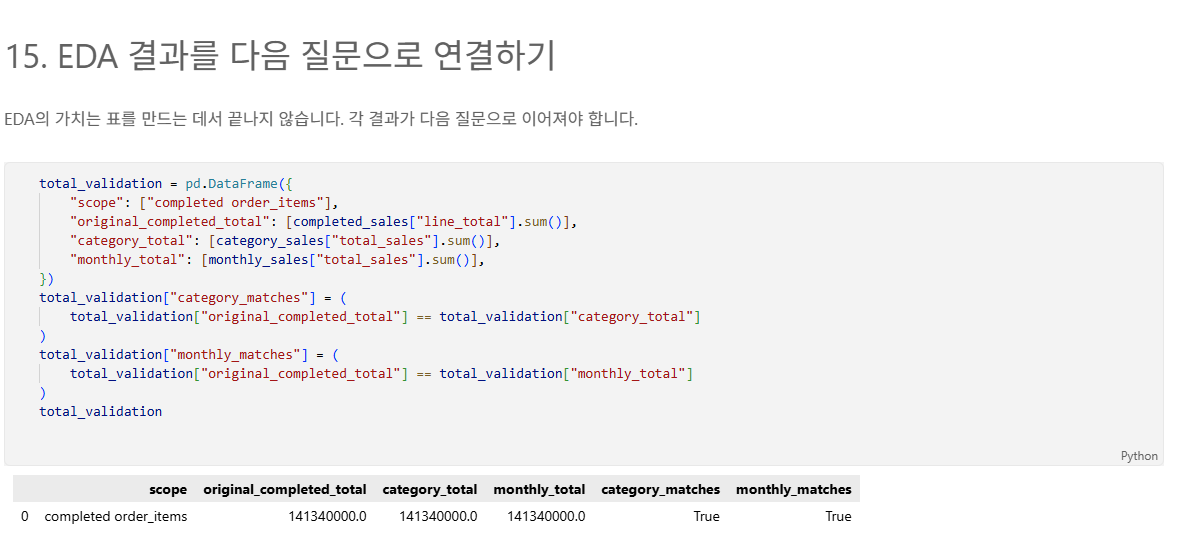

### 결과 관찰
completed 범위에서 패션 카테고리의 매출이 가장 높다. 도시별로는 부산의 completed 매출이 가장 높다. 상품 참조가 없는 주문상세는 Unmapped으로 남겨 전체 매출에 포함했다.

### 나의 해석과 판단
매출 상위 카테고리는 판매 수량이 많거나 평균 단가가 높을 가능성이 있지만, 현재 결과만으로 어느 요인이 원인인지는 단정할 수 없다. 범주·월별 합계가 원본 합계와 일치하므로 동일 범위를 사용한 집계라는 점은 확인됐다.

### 업무·분석적 의미
매출이 큰 카테고리와 도시를 우선 관찰 대상으로 삼을 수 있으며, 다음 분석에서는 수량·단가·주문 횟수를 분리해 검토할 수 있다.

### 한계와 추가 확인 사항
주문 수가 적은 집단의 매출은 큰 한 건의 주문에 좌우될 수 있다. 할인, 마케팅 노출, 재고 정보가 없어 매출 차이의 원인을 설명할 수는 없다.

## 3. 관찰 → 가설 → 추가 검증
### 사례 1
- 관찰: 패션가 completed 매출 1위다.
- 가설: 판매 수량이 많거나 평균 단가가 다른 카테고리보다 높을 수 있다.
- 추가 검증: 카테고리별 판매 수량, 평균 단가, 주문당 금액을 함께 비교한다.

### 사례 2
- 관찰: 부산의 completed 매출이 가장 높다.
- 가설: 해당 도시의 고객 수가 많거나 고객당 주문 횟수가 높을 수 있다.
- 추가 검증: 도시별 고객 수, 고객당 주문 수, 주문당 평균 금액을 나누어 비교한다.

### 사례 3
- 관찰: 일부 주문상세는 상품 카테고리를 찾지 못해 Unmapped으로 분류됐다.
- 가설: Chapter 05에서 오류 가격 상품을 제외한 영향 또는 원본 FK 오류일 수 있다.
- 추가 검증: Unmapped 주문상세의 product_id와 원본 products 데이터를 다시 대조한다.

## 4. LLM 질문 확장
- Safe Context: completed 주문 179개, 주문상세 446개와 카테고리·월·도시별 집계만 제공했다.
- Prompt: completed 주문 기준 카테고리·월·도시별 매출 집계가 있다. 원인을 단정하지 않고 다음 EDA 질문 3개와 각 검증 지표를 제안해줘.
- LLM 제안 요약: 매출 차이를 판매 수량·평균 단가·고객 수·주문당 금액으로 분해하고, 특정 월의 변화와 Unmapped 상품을 추가 점검하라고 제안했다.
- 실제 사용 여부: 수정 후 사용
- 판단 이유: 집계 확장 방향은 유용하지만, 현재 데이터에 없는 할인·광고·재고 정보를 이미 존재하는 것처럼 가정하지 않도록 수정했다.
- 사람이 수정한 내용: 모든 제안을 현재 컬럼으로 계산 가능한 지표로 제한하고, 인과 결론 대신 추가 검증 질문으로 표현했다.

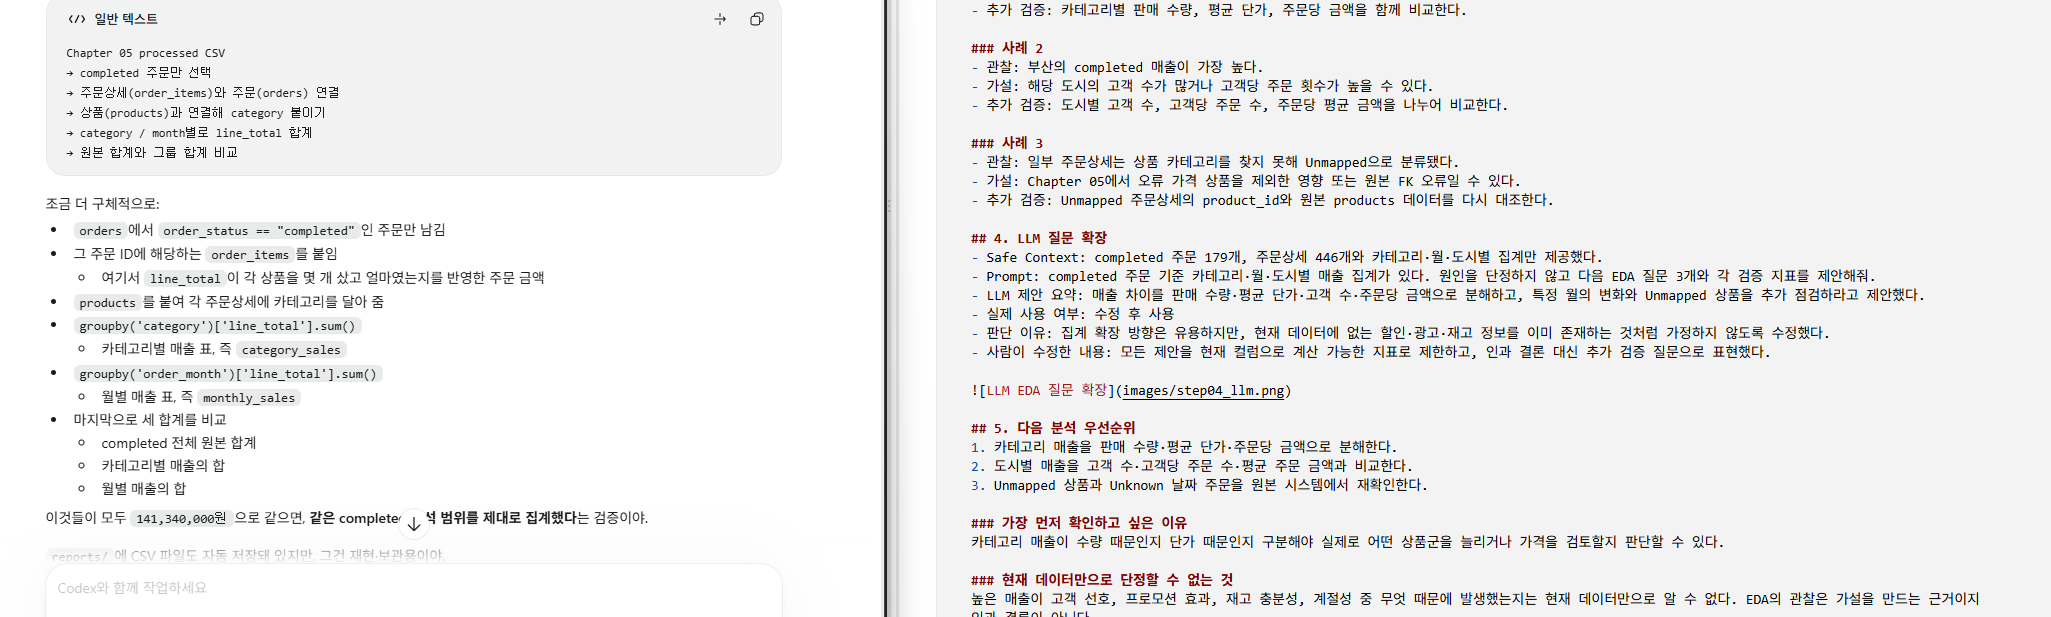

## 5. 다음 분석 우선순위
1. 카테고리 매출을 판매 수량·평균 단가·주문당 금액으로 분해한다.
2. 도시별 매출을 고객 수·고객당 주문 수·평균 주문 금액과 비교한다.
3. Unmapped 상품과 Unknown 날짜 주문을 원본 시스템에서 재확인한다.

### 가장 먼저 확인하고 싶은 이유
카테고리 매출이 수량 때문인지 단가 때문인지 구분해야 실제로 어떤 상품군을 늘리거나 가격을 검토할지 판단할 수 있다.

### 현재 데이터만으로 단정할 수 없는 것
높은 매출이 고객 선호, 프로모션 효과, 재고 충분성, 계절성 중 무엇 때문에 발생했는지는 현재 데이터만으로 알 수 없다. EDA의 관찰은 가설을 만드는 근거이지 인과 결론이 아니다.

## 최종 체크
- [x] 질문과 지표가 연결되어 있습니다.
- [x] 집계 총합을 검증했습니다.
- [x] 관찰과 가설을 구분했습니다.
- [x] 다음 검증 질문을 작성했습니다.
- [x] LLM 제안을 검증했습니다.
- [x] 최종 Notebook URL을 제출합니다.


## 증빙 이미지 최신본 확인

PNG를 다시 저장한 뒤 바로 아래 셀만 실행하면 최신 이미지를 확인할 수 있습니다.

In [ ]:
# 증빙 이미지 즉시 새로고침
# PNG를 다시 저장한 뒤 이 셀만 실행하면 최신 원본을 직접 표시합니다.
from pathlib import Path
from IPython.display import Image as DisplayImage, display


def find_chapter06(start: Path) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if candidate.name == "chapter06" and (candidate / "images").exists():
            return candidate
        nested = candidate / "chapter06"
        if (nested / "images").exists():
            return nested
    raise FileNotFoundError("chapter06/images를 찾지 못했습니다.")


preview_root = find_chapter06(Path.cwd())
for preview_name in ["step02_eda.png", "step04_llm.png"]:
    preview_path = preview_root / "images" / preview_name
    print(f"{preview_name} | {preview_path.stat().st_size:,} bytes")
    display(DisplayImage(filename=str(preview_path)))
